# 1. Очистка данных

Сперва мы должны привести все данные в единообразный формат, пригодный для расчёта статистики и построения моделей.

In [ ]:
import pandas as pd

In [ ]:
# загрузим и проверим данные

surg = pd.read_excel('DATA_SURGERY.xlsx', header=1)
surg = surg.set_index('ID')
surg = surg.iloc[:, :12]

surg.sample(n=5)

In [ ]:
surg.info()

<class 'pandas.core.frame.DataFrame'>
Index: 928 entries, 1 to 928
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Был ли эвейк?         921 non-null    object 
 1   Учреждение            923 non-null    object 
 2   возраст               883 non-null    float64
 3   пол                   903 non-null    object 
 4   рукость               880 non-null    object 
 5   монолингв             786 non-null    object 
 6   уровень образования   672 non-null    object 
 7   первичный /вторичный  879 non-null    object 
 8   полушарие             877 non-null    object 
 9   локализация           861 non-null    object 
 10  опухоль               812 non-null    object 
 11  WHO grade             663 non-null    object 
dtypes: float64(1), object(11)
memory usage: 94.2+ KB


In [ ]:
surg.isna().sum()

,0
Был ли эвейк?,7
Учреждение,5
возраст,45
пол,25
рукость,48
монолингв,142
уровень образования,256
первичный /вторичный,49
полушарие,51
локализация,67


В столбцах очень много NaN значений, с ними придётся разбираться. Мы их исключим, поскольку нужны чистые данные.

Часть столбцов мы тоже сразу исключим, не считая их значимыми для нашего исследования.

In [ ]:
del surg["Был ли эвейк?"] # нерелевантно посколько мы рассматриваем данные дооперационного тестирования
del surg["Учреждение"] # нерелевантно для наших целей
del surg["уровень образования"] # не считаем значимым
del surg["WHO grade "] # пояснение см. внизу раздела

In [ ]:
surg.dropna(inplace=True)

In [ ]:
surg.info()

<class 'pandas.core.frame.DataFrame'>
Index: 695 entries, 44 to 928
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   возраст               695 non-null    float64
 1   пол                   695 non-null    object 
 2   рукость               695 non-null    object 
 3   монолингв             695 non-null    object 
 4   первичный /вторичный  695 non-null    object 
 5   полушарие             695 non-null    object 
 6   локализация           695 non-null    object 
 7   опухоль               695 non-null    object 
dtypes: float64(1), object(7)
memory usage: 48.9+ KB


In [ ]:
# посмотрим на некоторые строчки из нашего датафрейма теперь

surg.sample(n=5)

Обработаем столбец `"пол"`

In [ ]:
surg["пол"].unique()

array(['ж', 'м', 'м ', 'М', 'Ж'], dtype=object)

In [ ]:
sex = {"м ":"м", 'М':"м", "Ж":"ж"}
surg["пол"] = surg["пол"].replace(sex)

Обработаем столбец `"рукость"`

In [ ]:
surg["рукость"].unique()

array(['правша', 'левша', 'переученная левша', 'амбидекстр',
       '(переученная?) левша', 'переученный левша',
       'правша (переученная?)',
       'амбидекстр (не знает, переучивали ли и есть родственники левши)',
       'говорит, что пишет правой рукой, а все остальное делает левой',
       'правша(пробовал научиться писать левой)', 'Правша',
       'правша (возможно, переученная)', 'правша ',
       'правша (ест, пишет) и левша (ручной труд, режет и т.п.)',
       'правша, но недавно потеряла пальцы на правой руке, переучивается на левую',
       'правша/левша (пишет правой, все остальное делает левой)',
       'правша/левша (правой пишет, левая сильнее, но домашние дела может делать обеими)',
       'амбидекстр (пишет правой, все остальное левой, в детстве был левшой) ',
       'Правша ',
       'правша (правая рука парализована, пишет левой, но неразборчиво)',
       'переученная правша (была левша)',
       'правша (иногда использует левую)', 'правша(переученный левша)',
    

In [ ]:
handedness_direct = {
    "правша" : ['правша(пробовал научиться писать левой)', 'Правша', 'правша ', 'Правша ', 'правша (иногда использует левую)', 'правша, но недавно потеряла пальцы на правой руке, переучивается на левую', 'правша (правая рука парализована, пишет левой, но неразборчиво)'],
    "левша" : ['говорит, что пишет правой рукой, а все остальное делает левой', 'правша/левша (пишет правой, все остальное делает левой)'],
    "амбидекстр" : ['амбидекстр (не знает, переучивали ли и есть родственники левши)', 'правша (ест, пишет) и левша (ручной труд, режет и т.п.)', 'правша/левша (правой пишет, левая сильнее, но домашние дела может делать обеими)', 'амбидекстр (пишет правой, все остальное левой, в детстве был левшой) '],
    "переуч левша" : ['переученная левша', '(переученная?) левша', 'переученный левша', 'правша (переученная?)', 'правша (возможно, переученная)', 'переученная правша (была левша)', 'правша (переученный левша)', 'правша(переученный левша)', 'правша (переученный?)']
}

In [ ]:
handedness_inverse = {}
for k in handedness_direct.keys():
  for v in handedness_direct[k]:
      handedness_inverse.update({v:k})

In [ ]:
surg["рукость"] = surg["рукость"].replace(handedness_inverse)
surg = surg[surg["рукость"] != 'билатеральность по EHI']

In [ ]:
# поскольку амбидекстров, переученных левшей и просто левшей даже в сумме очень мало, мы объединим эти подтипы

surg["рукость"] = surg["рукость"].replace({"левша": "не-правша", "переуч левша":"не-правша", "амбидекстр":"не-правша"})

In [ ]:
surg["рукость"].value_counts()

,count
рукость,
правша,626
не-правша,68


Обработаем столбец "монолингв"

In [ ]:
surg["монолингв"] = surg["монолингв"].str.lower()
surg["монолингв"] = surg["монолингв"].str.strip()

In [ ]:
surg["монолингв"].unique()

array(['да', 'нет: русский + чувашский', 'нет: русский+азербайджанский',
       'нет: русский+армянский', 'нет: армянский + русский',
       'нет (родной - мордовский)', 'билингв (татарский + русский)',
       'билингв (киргиз + рус)', 'билингв (чеченский)',
       'билингв (русско-чувашский)', 'нет (чеченский)', 'нет (татарский)',
       'да (учил франц?)', 'нет (русский+чеченский)',
       'нет (аварский + русский с 7 лет)', 'нет (чувашский  + русский)',
       'нет  (мордовский, несбаланс. - живет в морд. деревне, с семьей говорит на морд.)',
       'нет (татарский +русский)',
       'да(много лет изучает английский, не говорит на нем, но слушает аудиокниги)',
       'да (много лет изучает английский)', 'нет (рус + ингушский)',
       'да (английский в школе)', 'да (в колледже- латинский, англ)',
       'нет (узбекский + русский)', 'нет (русский + узбекский)',
       'да (учил французский в школе)', 'да (учил в школе немецкий)',
       'да (читает и переводит со словарём с немецкого

In [ ]:
surg["монолингв"] = surg["монолингв"].replace('да.*', "да", regex=True)
surg["монолингв"] = surg["монолингв"].replace('нет.*', "нет", regex=True)
surg["монолингв"] = surg["монолингв"].replace('билингв.*', "нет", regex=True)
surg["монолингв"] = surg["монолингв"].replace({"татарский": "нет", "кабардинский" : "нет", "чувашский" : "нет"})

Обработаем столбец "первичный /вторичный"

In [ ]:
surg = surg.rename(columns={"первичный /вторичный": "операция"})

In [ ]:
surg["операция"].unique()

array(['первичный', 'вторичный (делали биопсию)', 'вторичный',
       'первичный (после стерео-ээг)', 'вторичный (после электродов)',
       'первичный после электродов', 'третья операция',
       'первичный (после электродов)', 'пятая операция', 'первичный ',
       'Первичный', 'первичный (после биопсии)', 'первичный после стерео',
       'Первичный ', 'третичный', 'третья ', 'третья',
       'первичный после биопсии', 'четвертая операция',
       'вторичный (2 месяца)', 'продолженный рост',
       'первичный (после стерео)', 'первичная ', 'третья операция ',
       'первичное'], dtype=object)

In [ ]:
operation_direct = {
    "первая" : ['первичный', 'первичный (после стерео-ээг)', 'первичный после электродов', 'первичный ', 'Первичный', 'первичный после биопсии', 'первичный (после стерео)', 'первичная ', 'первичный (после электродов)', 'первичный (после биопсии)', 'первичный после стерео', 'Первичный ', 'первичное'],
    "вторая+" : ['вторичный (делали биопсию)', 'вторичный', 'вторичный (после электродов)', 'пятая операция', 'третья ', 'третья', 'четвертая операция', 'вторичный (2 месяца)', 'продолженный рост', 'третья операция', 'третичный', 'третья операция ']
}

In [ ]:
operation_inverse = {}
for k in operation_direct.keys():
  for v in operation_direct[k]:
      operation_inverse.update({v:k})

In [ ]:
surg["операция"] = surg["операция"].replace(operation_inverse)

Обработаем столбец `"полушарие"`

In [ ]:
surg["полушарие"].unique()

array(['левое', 'правое', ' левое и правое', 'левое и правое', 'левое ',
       'Левое', 'левое (+правое)'], dtype=object)

In [ ]:
surg["полушарие"] = surg["полушарие"].replace({"левое ":"левое", " левое и правое":"левое и правое", "Левое" : "левое", "левое (+правое)":"левое и правое"})

In [ ]:
surg["полушарие"].value_counts()

,count
полушарие,
левое,668
правое,18
левое и правое,8


In [ ]:
# данных по не-левому полушарию очень мало и много сложных случаев, мы их исключим

surg = surg[surg["полушарие"] != "правое"]
surg = surg[surg["полушарие"] != "левое и правое"]

In [ ]:
# теперь, когда осталось только левое полушарие, можно удалить этот признак, поскольку он имеет только одно значение

del surg["полушарие"]

Обработаем самый сложный и самый важный столбец -- `"локализация"`. Он будет являться целевой переменной в нашем исследовании, хотя позже скорее всего мы разобьём его на несколько колонок.

In [ ]:
surg["локализация"].unique()

array(['лобный', 'лобный, теменной',
       'левый лоб, висок, инсула (две опухоли)',
       'лобно-премоторная область', 'висок, инсула', 'височный',
       'лобный (SMA)', 'заднелобный', 'височный полюс, инсула',
       'височный полюс', 'височный и инсула',
       'висок (фузиформная извилина)', 'лоб', 'висок',
       'висок, лоб, инсула', 'лобный, инсула', 'висок (островок)',
       'лоб, висок (2 шт)', 'висок(островок)', 'темя',
       'лоб, темя-висок (2шт)', 'темя, висок',
       'задне-нижние отделы лобной области', 'лоб, висок, инсула',
       'лоб, мозолистое тело (проросла в ПП)', 'лоб, темя, висок',
       'висок ', 'лоб, темя', 'висок, инсула, лоб',
       'височно-теменно-затылочная область', 'висок, лоб',
       'висок (множеств)', 'лоб, висок', 'висок?',
       'лобно-височной области слева с распространением на островок',
       'инсула, крючок', 'висок, островковая доля',
       'Опухоль обеих лобных, левых височной и островковой долей и мозолистого тела.',
       'ви

In [ ]:
surg["локализация"] = surg["локализация"].str.lower()
surg["локализация"] = surg["локализация"].str.strip()

In [ ]:
# лоб > висок > темя

# остальные локализации мы исключаем, также для чистоты мы исключаем случаи, когда задеты какие-то локализации,
# кроме трёх указанных выше (например, исключаем "лоб, висок, инсула")

loc_direct = {
    "лоб" : ['лобный', 'лобно-премоторная область', 'лобный (sma)', 'заднелобный', 'лоб',
             'задне-нижние отделы лобной области', 'задние отделы нижней лобной извилины', 'лоб, задние отделы',
             'лоб, задне-нижние отделы', 'объемное образование левой лобной области',
             'объемные образования левой лобной доли: оперкулярной части и парасагиттальных отделов прецентральной извилины.',
             'левая лобная доля. состояние после оперативного лечения от 04.07.2018. продолженный рост опухоли.',
             'левый лоб', 'задние отделы лев лоб', 'лоб (лобнокаллезная область)', 'лоб (премоторная зона)'],
    "лоб, висок" : ['лоб, висок (2 шт)', 'висок, лоб', 'лоб, висок', 'объемное образование левой лобно-височной области',
                    'висок+лоб', 'лоб+висок', 'лоб + висок'],
    "лоб, темя" : ['лобный, теменной', 'лоб, темя', 'лобно-теменная область', 'лоб + темя'],
    "висок" : ['височный', 'височный полюс', 'висок (фузиформная извилина)', 'висок', 'висок (множеств)', 'висок?',
               'объемное образование левой височной области', 'висок, полюс', 'эпивисок'],
    "висок, темя" : ['темя, висок', 'височно-теменная область', 'висок, темя', 'висок+темя', 'висок темя', 'темя+висок',
                     'висок + темя', 'темя + висок', 'висок, темы', 'висок селективно'],
    "темя" : ['темя', 'супрамаргинальна изв.'],
    "лоб, висок, темя" : ['лоб, темя-висок (2шт)', 'лоб, темя, висок', 'темя, висок, лоб', 'лоб, висок, темя', 'лоб темя висок']
}

In [ ]:
loc_inverse = {}
for k in loc_direct.keys():
  for v in loc_direct[k]:
      loc_inverse.update({v:k})

In [ ]:
# исключим все лишние значения

surg = surg[surg["локализация"].isin(loc_inverse.keys())]

In [ ]:
surg["локализация"] = surg["локализация"].replace(loc_inverse)

In [ ]:
surg["локализация"].value_counts()

,count
локализация,
висок,322
лоб,168
темя,26
"висок, темя",21
"лоб, висок",21
"лоб, темя",14
"лоб, висок, темя",9


Обработаем столбец `"опухоль"`. На самом деле, нас не интересует конкретный характер опухоли -- нам важно наличие или отстуствие эпилепсии, поэтому мы можем превратить этот столбец в бинарный признак `is_epileptic`

In [ ]:
surg = surg.rename(columns={"опухоль": "is_epileptic"})

In [ ]:
surg["is_epileptic"].unique()

array(['анапластическая астроцитома', 'олигодендроглиома',
       'анапластическая олигодендроглиома',
       'олигодендроглиома или диффузная астроцитома',
       'диффузная астроцитома', 'олигоастроцитома',
       'анапластическая глиома', 'астроцитома', 'ганглиоглиома',
       'опухоли нет, производилась резекция эпилептического очага. по гистологии: очаговый глиоз, кровоизлияния.',
       'очаговый глиоз (может соответствовать посттравмаическим изменениям)',
       'глиобластома',
       'анапластическая олигодендроглиома или анапластическая астроцитома',
       'олигодендроглиома/диффузная астроцитома', 'кавернома', 'склероз',
       'метастаз', 'эпиочаг', 'получить повторно',
       'анапластическая астроцитома ', 'эпи', 'МР-негативная эпилепсия',
       'рубцы в неокортексе', 'эпи; кавернома? нейроглиальная опухоль?',
       'глиосаркома', 'диффузная астроцитома и ФКД IIIb',
       'дифф астроцитома с участками анапласт трансф-ии',
       'диффузная астроцитома ',
       'каверн

In [ ]:
epi = ['опухоли нет, производилась резекция эпилептического очага. по гистологии: очаговый глиоз, кровоизлияния.',
       'эпиочаг', 'эпи', 'МР-негативная эпилепсия', 'эпи; кавернома? нейроглиальная опухоль?', 'диффузная астроцитома и ФКД IIIb',
       'кавернозная гемангиома, симптоматическая эпи', 'ФКД + дифф астро', 'эпи (киста висок-лоб)', 'ФКД', 'эпи (вызванная кистой?)',
       'эпи + фкд', 'эпи, фкд', 'фкд', 'эпи (ОО в выписке, киста в гистологии)', 'эпи + ФКД',
       'эпи (ОО в выписке, в гистологии не указано наличие ОО)', 'эпи + кавернома', 'эпи (фкд)', 'эпи (дермоидная киста, глиоз)',
       'опухоль, эпи', 'эпи ', 'эпи селективно']

In [ ]:
surg["is_epileptic"] = [1 if x in epi else 0 for x in surg["is_epileptic"]]

In [ ]:
surg["is_epileptic"].value_counts()

,count
is_epileptic,
0,353
1,228


Обработаем столбец `"WHO grade "`.

Изначально планировалось, что для случаев эпилепсии без опухоли мы поставим значение 0. Тем не менее, как мне кажется, не имеет большого смысла включать стадию в признаки, поскольку мы пытаемся выяснить локализацию опухоли по признакам -- очевидно, мы не можем одновременно знать стадию и не знать локализацию (задача получается очень искусственной).

Вместе с тем, если включить стадию в целевую переменную, то модель должна будет с одной стороны выдавать бинарную классификацию локализации и регрессию для стадии, что невозможно.

В связи с вышесказанным, мы решили удалить этот столбец из наших данных (сделано вначале).

Наконец, проверим получившийся обработанный датасет:

In [ ]:
surg.sample(n=10)

# 2. Объединим получившийся датафрейм с данными РАТ

In [ ]:
# загрузим и проверим данные

rat = pd.read_excel('rat.xlsx', header=0)
rat = rat.iloc[:, :15]

rat.sample(n=5)

оставим только строчки с дооперационным тестированием

In [ ]:
rat["timing"].unique()

array(['до', 'кат', 'после', 'катамнез', 'до 1', 'До', 'После', 'кат.',
       'после ', 'до ', 'да'], dtype=object)

In [ ]:
t = {
    "до 1" : "до",
    "До" : "до",
    "После" : "после",
    'после ' : "после",
    'до ' : "до",
    'да' : "до"
}

rat["timing"] = rat["timing"].replace(t)

In [ ]:
rat = rat[rat['timing'] == "до"]

In [ ]:
del rat["timing"]

In [ ]:
rat.set_index('ID', inplace=True)
rat.head()

Объединим два наших датафрейма по ID пациентов

In [ ]:
total = pd.merge(surg, rat, left_on='ID', right_on='ID', how='inner')

In [ ]:
total.info()

<class 'pandas.core.frame.DataFrame'>
Index: 553 entries, 44 to 927
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   возраст                      553 non-null    float64
 1   пол                          553 non-null    object 
 2   рукость                      553 non-null    object 
 3   монолингв                    553 non-null    object 
 4   операция                     553 non-null    object 
 5   локализация                  553 non-null    object 
 6   is_epileptic                 553 non-null    int64  
 7   Pseudo.perc                  524 non-null    float64
 8   Lex.dec                      526 non-null    float64
 9   Noun.comp                    534 non-null    float64
 10  Verb.comp                    538 non-null    float64
 11  Synt.comp                    522 non-null    float64
 12  Disc.comp                    515 non-null    object 
 13  Pseudo.repetition       

In [ ]:
total.sample(n=5)

In [ ]:
total['Disc.comp'] = total['Disc.comp'].astype('float64')
total['Pseudo.repetition'] = total['Pseudo.repetition'].astype('float64')

<Axes: xlabel='ID'>

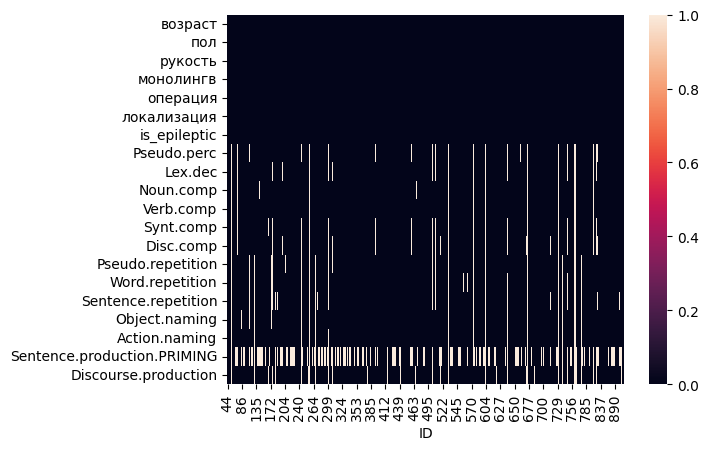

In [ ]:
import seaborn as sns

sns.heatmap(total.isna().transpose())

# 3. Закодируем признаки для удобства работы с ними

In [ ]:
import numpy as np

In [ ]:
total.sample(n=5)

In [ ]:
new_names = {"возраст":"age",
             "пол":"is_male",
             "рукость":"is_excl_RH",
             "монолингв":"is_monolingual",
             "операция":"first_op",
             }

total = total.rename(columns=new_names)

In [ ]:
total["is_male"] = [1 if x == "м" else 0 for x in total["is_male"]]
total["is_excl_RH"] = [1 if x == "правша" else 0 for x in total["is_excl_RH"]]
total["is_monolingual"] = [1 if x == "да" else 0 for x in total["is_monolingual"]]
total["first_op"] = [1 if x == "первая" else 0 for x in total["first_op"]]

In [ ]:
# строку "локализация" мы разделим на три отдельных строки по принципу one-hot encoding для одиночных категорий

total.insert(6, 'frontal', np.zeros(553))
total.insert(7, 'temporal', np.zeros(553))
total.insert(8, 'parietal', np.zeros(553))

In [ ]:
total['frontal'] = total['frontal'].astype('int64')
total['temporal'] = total['temporal'].astype('int64')
total['parietal'] = total['parietal'].astype('int64')

In [ ]:
frontal = ["лоб", "лоб, висок", "лоб, темя", "лоб, висок, темя"]
temporal = ["висок", "висок, темя", "лоб, висок", "лоб, висок, темя"]
parietal = ["темя", "висок, темя", "лоб, темя", "лоб, висок, темя"]

total["frontal"] = [1 if x in frontal else 0 for x in total["локализация"]]
total["temporal"] = [1 if x in temporal else 0 for x in total["локализация"]]
total["parietal"] = [1 if x in parietal else 0 for x in total["локализация"]]

In [ ]:
del total["локализация"]

In [ ]:
total.sample(n=5)

In [ ]:
total.to_csv("total.csv")

# 4. Посмотрим на статистические закономерности

В частности посмотрим на:

* распределение, медиана и среднее разных значений, разброс
* матрица корреляций
* p-value распределения локализаций в зависимости от данных РАТ

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

total = pd.read_csv("total.csv")

In [ ]:
total["age"].max()

74.0

In [ ]:
# объединим данные по субтестам, далее будем работать с ними

total["Comp"] = total[["Pseudo.perc", "Lex.dec", "Noun.comp", "Verb.comp", "Synt.comp", "Disc.comp"]].mean(axis=1)
total["Rep"] = total[["Pseudo.repetition", "Word.repetition", "Sentence.repetition"]].mean(axis=1)
total["Prod"] = total[["Object.naming", "Action.naming", "Sentence.production.PRIMING", "Discourse.production"]].mean(axis=1)

tests = ["Pseudo.perc", "Lex.dec", "Noun.comp", "Verb.comp", "Synt.comp", "Disc.comp", "Pseudo.repetition", "Word.repetition", "Sentence.repetition", "Object.naming", "Action.naming", "Sentence.production.PRIMING", "Discourse.production"]
total = total.drop(columns=tests)

In [ ]:
# удалим NA

total = total.dropna()

In [ ]:
total.shape

(522, 13)

check

In [ ]:
del total[]

4.1.1. Взглянем на распределение наших данных

TypeError: FigureCanvasAgg.print_png() got an unexpected keyword argument 'figsize'

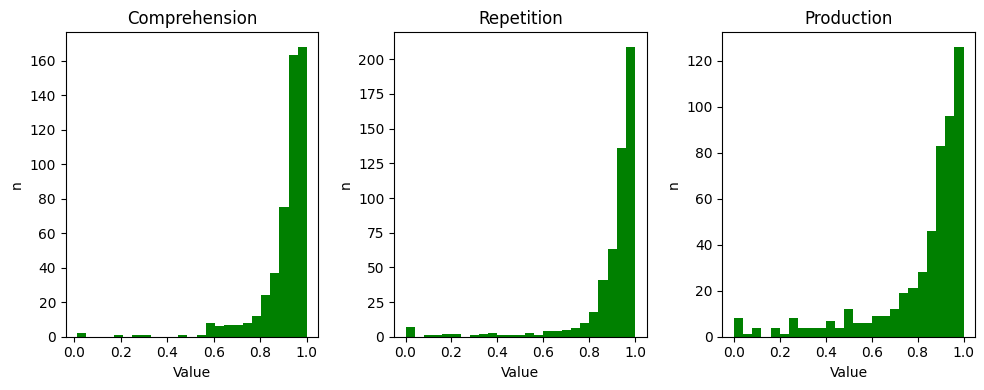

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

total["Comp"].plot.hist(ax=axes[0], bins=25, color="green")
axes[0].set_title("Comprehension")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("n")

total["Rep"].plot.hist(ax=axes[1], bins=25, color="green")
axes[1].set_title("Repetition")
axes[1].set_xlabel("Value")
axes[1].set_ylabel("n")

total["Prod"].plot.hist(ax=axes[2], bins=25, color="green")
axes[2].set_title("Production")
axes[2].set_xlabel("Value")
axes[2].set_ylabel("n")

plt.tight_layout()
plt.savefig('distr.pdf', format='pdf')

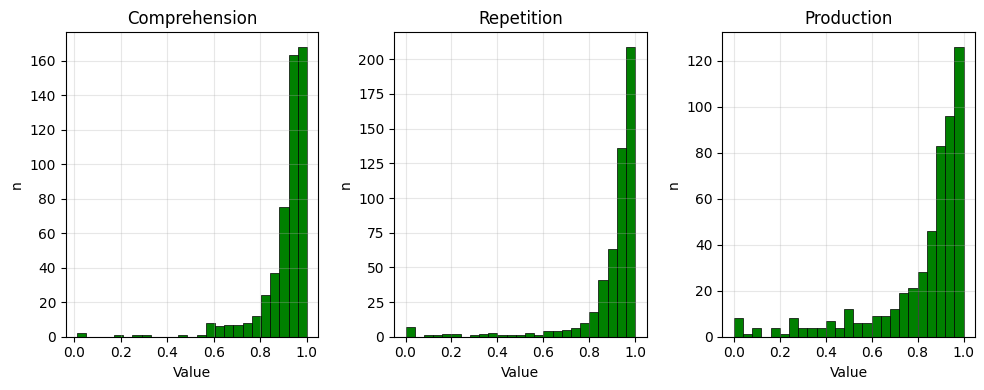

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

# Используем numpy.histogram + bar — 100% векторно
for ax, column, title in zip(axes, ["Comp", "Rep", "Prod"],
                              ["Comprehension", "Repetition", "Production"]):
    counts, bins, _ = ax.hist(total[column], bins=25, color="green", edgecolor="black", linewidth=0.5)
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("n")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('distr.png', dpi=600, bbox_inches='tight')

In [ ]:
q75, q25 = np.percentile(total["Prod"], [75, 25])
iqr = q75 - q25
print("iqr = ", iqr)

iqr =  0.1793176328502416


4.1.1.1. Поскейлим возраст

In [ ]:
# скейлинг возраста

print(total["age"].mean())
print(total["age"].std())

total["age"] = [x - total["age"].mean() for x in total["age"]]
total["age"] = [x / total["age"].std() for x in total["age"]]

39.36206896551724
13.667744294465036


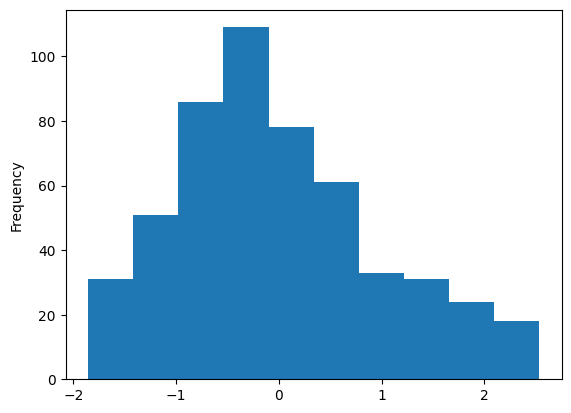

In [ ]:
total["age"].plot.hist()
plt.show()

Данные очень сильно несбалансированы, поскольку большинство пациентов хорошо справляется с тестами. Тем не менее, дисбаланс немного отличается.

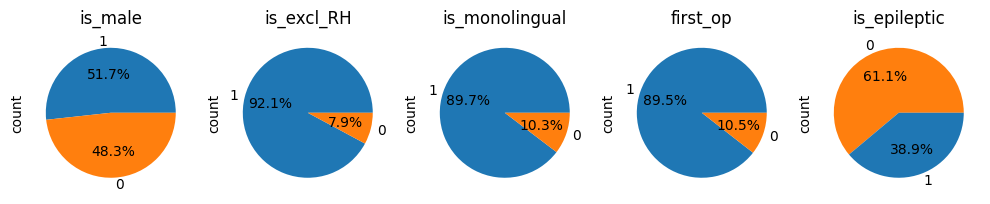

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(10, 4))

total["is_male"].value_counts().plot.pie(ax=axes[0], autopct='%1.1f%%')
axes[0].set_title("is_male")

total["is_excl_RH"].value_counts().plot.pie(ax=axes[1], autopct='%1.1f%%')
axes[1].set_title("is_excl_RH")

total["is_monolingual"].value_counts().plot.pie(ax=axes[2], autopct='%1.1f%%')
axes[2].set_title("is_monolingual")

total["first_op"].value_counts().plot.pie(ax=axes[3], autopct='%1.1f%%')
axes[3].set_title("first_op")

total["is_epileptic"].value_counts().plot.pie(ax=axes[4], autopct='%1.1f%%', colors=["tab:orange", "tab:blue"])
axes[4].set_title("is_epileptic")

plt.tight_layout()
plt.show()

Данные по билингвальности, праворукости и количеству операций также сильно несбалансированы. Посмотрим, как они повлияют.

<Axes: ylabel='count'>

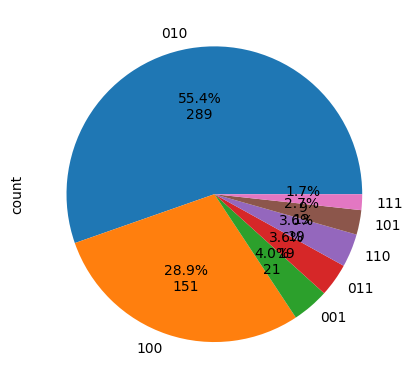

In [ ]:

total['lesion'] = total['frontal'].astype(str) + total['temporal'].astype(str) + total['parietal'].astype(str)
#total.loc[total['lesion'] == '001', 'lesion'] = 'parietal'
#total.loc[total['lesion'] == '010', 'lesion'] = 'temporal'
#total.loc[total['lesion'] == '011', 'lesion'] = 'temporoparietal'
#total.loc[total['lesion'] == '100', 'lesion'] = 'frontal'
#total.loc[total['lesion'] == '101', 'lesion'] = 'frontoparietal'
#total.loc[total['lesion'] == '110', 'lesion'] = 'frontotemporal'
#total.loc[total['lesion'] == '111', 'lesion'] = 'frontotemporoparietal'
freq = total['lesion'].value_counts()

freq.plot.pie(autopct=lambda p: f'{p:.1f}%\n{int(p/100.*sum(freq))}')
#plt.savefig('pat.png', dpi=600)

In [ ]:
total["lesion"].value_counts()

,count
lesion,
010,289
100,151
001,21
011,19
110,19
101,14
111,9


Наиболее рациональной стратегией в дальнейшем будет использовать решающие деревья, поскольку они лучше справляются с дисбалансом данных.

4.1.2. Построим ящики с усами для наших данных, вычислим базовые характеристики (среднее, медиана, стандартное отклонение)

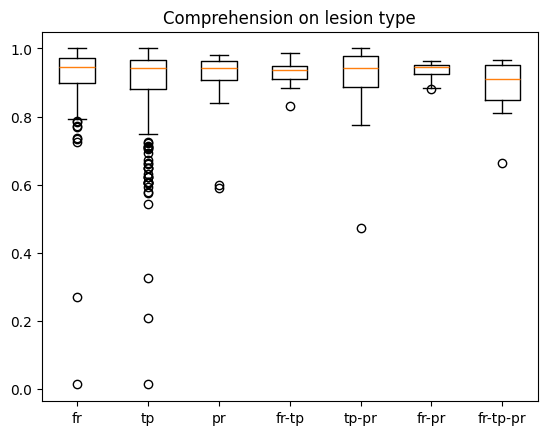

In [ ]:
plt.boxplot([total[total["lesion"] == "100"]["Comp"],
            total[total["lesion"] == "010"]["Comp"],
            total[total["lesion"] == "001"]["Comp"],
            total[total["lesion"] == "110"]["Comp"],
             total[total["lesion"] == "011"]["Comp"],
             total[total["lesion"] == "101"]["Comp"],
             total[total["lesion"] == "111"]["Comp"]])
plt.title("Comprehension on lesion type")
plt.xticks([1, 2, 3, 4, 5, 6, 7], ['fr', 'tp', 'pr', 'fr-tp', 'tp-pr', 'fr-pr', 'fr-tp-pr'])
plt.savefig('comp.png', dpi=600)

In [ ]:
# посчитаем медиану и стандартное отклонение
total[total["lesion"] == "010"]["Comp"].std()

0.1234215794355729

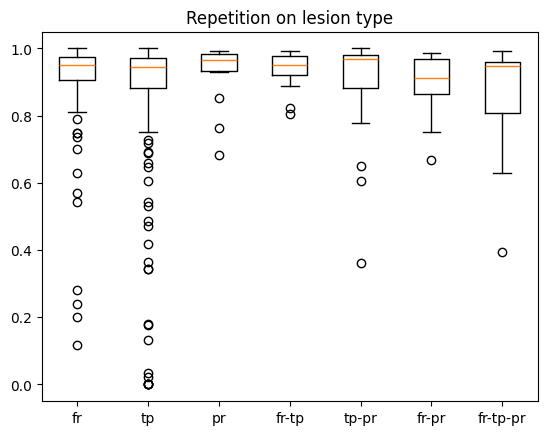

In [ ]:
plt.boxplot([total[total["lesion"] == "100"]["Rep"],
            total[total["lesion"] == "010"]["Rep"],
            total[total["lesion"] == "001"]["Rep"],
            total[total["lesion"] == "110"]["Rep"],
             total[total["lesion"] == "011"]["Rep"],
             total[total["lesion"] == "101"]["Rep"],
             total[total["lesion"] == "111"]["Rep"]])
plt.title("Repetition on lesion type")
plt.xticks([1, 2, 3, 4, 5, 6, 7], ['fr', 'tp', 'pr', 'fr-tp', 'tp-pr', 'fr-pr', 'fr-tp-pr'])
plt.savefig('rep.png', dpi=600)

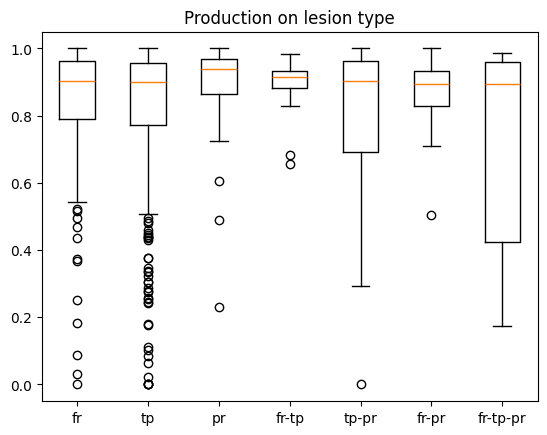

In [ ]:
plt.boxplot([total[total["lesion"] == "100"]["Prod"],
            total[total["lesion"] == "010"]["Prod"],
            total[total["lesion"] == "001"]["Prod"],
            total[total["lesion"] == "110"]["Prod"],
             total[total["lesion"] == "011"]["Prod"],
             total[total["lesion"] == "101"]["Prod"],
             total[total["lesion"] == "111"]["Prod"]])
plt.title("Production on lesion type")
plt.xticks([1, 2, 3, 4, 5, 6, 7], ['fr', 'tp', 'pr', 'fr-tp', 'tp-pr', 'fr-pr', 'fr-tp-pr'])
plt.savefig('prod.png', dpi=600)

4.2. Посчитаем p-value для нашего распределения

In [ ]:
import scipy.stats as sp

fr_comp = total[total["lesion"] == "100"]["Comp"]
tp_comp = total[total["lesion"] == "010"]["Comp"]
pr_comp = total[total["lesion"] == "001"]["Comp"]
fr_tp_comp = total[total["lesion"] == "110"]["Comp"]
tp_pr_comp = total[total["lesion"] == "011"]["Comp"]
fr_pr_comp = total[total["lesion"] == "101"]["Comp"]
fr_tp_pr_comp = total[total["lesion"] == "111"]["Comp"]
print('comprehension p-value: ',
float(sp.kruskal(fr_comp, tp_comp, pr_comp, fr_tp_comp, tp_pr_comp, fr_pr_comp, fr_tp_pr_comp).pvalue)
)

fr_rep = total[total["lesion"] == "100"]["Rep"]
tp_rep = total[total["lesion"] == "010"]["Rep"]
pr_rep = total[total["lesion"] == "001"]["Rep"]
fr_tp_rep = total[total["lesion"] == "110"]["Rep"]
tp_pr_rep = total[total["lesion"] == "011"]["Rep"]
fr_pr_rep = total[total["lesion"] == "101"]["Rep"]
fr_tp_pr_rep = total[total["lesion"] == "111"]["Rep"]
print('repetition p-value: ',
float(sp.kruskal(fr_rep, tp_rep, pr_rep, fr_tp_rep, tp_pr_rep, fr_pr_rep, fr_tp_pr_rep).pvalue)
)

fr_prod = total[total["lesion"] == "100"]["Prod"]
tp_prod = total[total["lesion"] == "010"]["Prod"]
pr_prod = total[total["lesion"] == "001"]["Prod"]
fr_tp_prod = total[total["lesion"] == "110"]["Prod"]
tp_pr_prod = total[total["lesion"] == "011"]["Prod"]
fr_pr_prod = total[total["lesion"] == "101"]["Prod"]
fr_tp_pr_prod = total[total["lesion"] == "111"]["Prod"]
print('production p-value: ',
float(sp.kruskal(fr_prod, tp_prod, pr_prod, fr_tp_prod, tp_pr_prod, fr_pr_prod, fr_tp_pr_prod).pvalue)
)

comprehension p-value:  0.561082297096043
repetition p-value:  0.23081429264604625
production p-value:  0.5694962711647538


Для всех типов:



```
comprehension p-value:  0.561082297096043
repetition p-value:  0.23081429264604625
production p-value:  0.5694962711647538
```



Итого, мы имеем p-value > 0.05 для всех категорий.


# 5. Проведём исследование на подвыборке

Подвыборка будет содержать пациентов с поражениями либо только в лобной, либо только в височной области, причём пациенты с эпилепсией будут исключены из выборки, поскольку для эпилепсии хорошо известна её связь с локализацией в виске. Работа с этой подвыборкой будет использована в качестве proof of concept.

5.1. Применим логистическую регрессию

In [ ]:
subsamp = total[(total["lesion"] == "100") | (total["lesion"] == "010")]
subsamp = subsamp[subsamp["is_epileptic"] == 1]
### ! changed dataset

In [ ]:
subsamp["lesion"].value_counts()

,count
lesion,
010,178
100,14


In [ ]:
X = np.column_stack([
    subsamp["age"],
    subsamp["is_male"],
    subsamp["is_excl_RH"],
    subsamp["is_monolingual"],
    subsamp["first_op"],
    subsamp["Comp"],
    subsamp["Rep"],
    subsamp["Prod"]
])

y = subsamp["frontal"].values.flatten()

# за y взята колонка frontal, поскольку в данной подвыборке 1 будет означать поражение лба, а 0 -- виска

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    shuffle = True,
    random_state = 42
)

In [ ]:
from sklearn.linear_model import LogisticRegressionCV

clf = LogisticRegressionCV(
    Cs = [0.5, 1.0, 5, 10],
    cv=5,
    scoring = 'roc_auc',
    solver = 'lbfgs',
    class_weight = 'balanced',
    verbose = 1,
    random_state = 42
)

clf = clf.fit(X_train, y_train)

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.4s finished


In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(clf, X_train, y_train, cv=5, scoring='roc_auc')

print(f"Mean ± Std: {np.mean(scores):.3f} ± {np.std(scores):.3f}")

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.4s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.2s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.3s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.3s finished


Mean ± Std: 0.554 ± 0.088


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.4s finished


In [ ]:
# Извлечение лучших параметров
best_C = clf.C_[0]
best_weights = clf.coef_

print(f"Лучший параметр C: {best_C}")
print(f"Лучшие коэффициенты модели: {best_weights}")

Лучший параметр C: 0.5
Лучшие коэффициенты модели: [[-0.19474815 -0.06902556 -0.12769059 -0.7203519  -0.54060448  0.2755722
   0.33624472  0.06394989]]


In [ ]:
y_pred = clf.predict(X_test)

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_test, y_pred)

np.float64(0.42)

5.2. Применим решающие деревья

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [1, 3, 5, 10, 50, 100],
    'criterion': ['gini', 'entropy'],
}

clf = DecisionTreeClassifier(random_state = 42)
grid_search = GridSearchCV(estimator=clf, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)

grid_search.fit(X_train, y_train)
print("Best parameters found:", grid_search.best_params_)
print("Best ROC-AUC score:", grid_search.best_score_)

model = grid_search.best_estimator_

Best parameters found: {'criterion': 'gini', 'max_depth': 1}
Best ROC-AUC score: 0.49563925702033124


In [ ]:
scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

print(f"Mean ± Std: {np.mean(scores):.3f} ± {np.std(scores):.3f}")

Mean ± Std: 0.496 ± 0.042


In [ ]:
y_pred = model.predict(X_test)
roc_auc_score(y_test, y_pred)

np.float64(0.52)

5.3. Применим случайный лес

In [ ]:
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [1, 5, 10, 25, 50, 100],
    'max_depth': [1, 3, 5, 10, 20, 50],
    'criterion': ['gini', 'entropy', 'log_loss'],
}

clf = RandomForestClassifier(random_state = 42)
grid_search = GridSearchCV(estimator=clf, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)

grid_search.fit(X_train, y_train)
print("Best parameters found:", grid_search.best_params_)
print("Best ROC-AUC score:", grid_search.best_score_)

model = grid_search.best_estimator_

Best parameters found: {'criterion': 'entropy', 'max_depth': 10, 'n_estimators': 10}
Best ROC-AUC score: 0.5583895218166319


In [ ]:
scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

print(f"Mean ± Std: {np.mean(scores):.3f} ± {np.std(scores):.3f}")

Mean ± Std: 0.558 ± 0.073


In [ ]:
y_pred = model.predict(X_test)
roc_auc_score(y_test, y_pred)

np.float64(0.46)

5.4. Применим градиентный бустинг

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

param_grid = {
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1],
    'n_estimators': [1, 5, 10, 25, 50, 100],
    'max_depth': [1, 3, 5, 10, 25],
    'verbose': [1]
}

clf = GradientBoostingClassifier(random_state=42)
grid_search = GridSearchCV(estimator=clf, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)

grid_search.fit(X_train, y_train)
print("Best parameters found:", grid_search.best_params_)
print("Best ROC-AUC score:", grid_search.best_score_)

model = grid_search.best_estimator_

      Iter       Train Loss   Remaining Time 
         1           1.3196            0.04s
         2           1.2983            0.03s
         3           1.2798            0.03s
         4           1.2574            0.02s
         5           1.2432            0.02s
         6           1.2284            0.02s
         7           1.2098            0.02s
         8           1.1958            0.02s
         9           1.1804            0.02s
        10           1.1660            0.02s
        20           1.0531            0.00s
Best parameters found: {'learning_rate': 1, 'max_depth': 1, 'n_estimators': 25, 'verbose': 1}
Best ROC-AUC score: 0.5297417913146814


In [ ]:
scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

print(f"Mean ± Std: {np.mean(scores):.3f} ± {np.std(scores):.3f}")

      Iter       Train Loss   Remaining Time 
         1           1.3267            0.04s
         2           1.2902            0.03s
         3           1.2613            0.03s
         4           1.2353            0.02s
         5           1.2158            0.02s
         6           1.1951            0.02s
         7           1.1749            0.02s
         8           1.1523            0.02s
         9           1.1337            0.02s
        10           1.1214            0.02s
        20           1.0072            0.00s
      Iter       Train Loss   Remaining Time 
         1           1.3353            0.03s
         2           1.3099            0.03s
         3           1.2871            0.03s
         4           1.2645            0.03s
         5           1.2419            0.02s
         6           1.2252            0.02s
         7           1.2088            0.02s
         8           1.1938            0.02s
         9           1.1688            0.02s
        

In [ ]:
y_pred = model.predict(X_test)
roc_auc_score(y_test, y_pred)

np.float64(0.5)

In [ ]:
# итого ничего не получилось

# 6. Проведём исследование на всей выборке

In [ ]:
total

In [ ]:
X = np.column_stack([
    total["age"],
    total["is_male"],
    total["is_excl_RH"],
    total["is_monolingual"],
    total["first_op"],
    total["is_epileptic"],
    total["Comp"],
    total["Rep"],
    total["Prod"]
])

Y = np.column_stack([
    total["frontal"],
    total["temporal"],
    total["parietal"]
])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size = 0.2,
    shuffle = True,
    random_state = 42
)

6.1. Применим регрессию

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier

lr = LogisticRegression(solver='lbfgs',
                        class_weight='balanced',
                        random_state=42)

multi_lr = MultiOutputClassifier(lr)

param_grid = {'estimator__C': [0.1, 0.5, 1.0, 5, 10]}

grid_search = GridSearchCV(
    estimator=multi_lr,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, Y_train)
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший Roc-AUC (macro):", grid_search.best_score_)
best_model = grid_search.best_estimator_

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Лучшие параметры: {'estimator__C': 0.1}
Лучший Roc-AUC (macro): 0.6902235838797119


In [ ]:
for i in range(3):
    single_model = best_model.estimators_[i]
    scores = cross_val_score(single_model, X_train, Y_train[:, i], cv=5, scoring='roc_auc')
    print(f"Target {i}: Mean AUC = {np.mean(scores):.3f} ± {np.std(scores):.3f}")

Target 0: Mean AUC = 0.738 ± 0.041
Target 1: Mean AUC = 0.709 ± 0.044
Target 2: Mean AUC = 0.627 ± 0.044


In [ ]:
Y_pred = best_model.predict(X_test)
print(roc_auc_score(Y_test, Y_pred, average=None))
print(roc_auc_score(Y_test, Y_pred, average="macro"))

[0.74192957 0.7196174  0.59526112]
0.6856026977797608


In [ ]:
import numpy as np

# Assume model is already trained
# model = MultiOutputClassifier(LogisticRegression()).fit(X_train, Y_train)

# 1. Access the list of fitted internal classifiers
internal_models = best_model.estimators_  # This returns a list, e.g., [lr_1, lr_2, lr_3]

# 2. Loop through them to get coefficients for each target
coefficients_per_target = []
for i, est in enumerate(internal_models):
    # For binary classification, coef_ shape is (1, n_features)
    coef = est.coef_[0]
    coefficients_per_target.append(coef)
    print(f"Feature importances for Target {i}: {coef}")

# 3. (Optional) Aggregate to get global importance
# Use the average of absolute coefficients across all targets
global_importance = np.mean(np.abs(coefficients_per_target), axis=0)
print(f"Global feature importance (average): {global_importance}")

Feature importances for Target 0: [ 0.1200504   0.00222116  0.07274376  0.14120186 -0.10493283 -1.53538883
  0.06301316  0.10667019  0.17281122]
Feature importances for Target 1: [-0.07166021 -0.03917152 -0.16171824 -0.02710703  0.08058997  1.41023439
 -0.02753123 -0.10602882 -0.14395148]
Feature importances for Target 2: [ 0.08282893 -0.11943244  0.1329167   0.08499572 -0.142913   -0.95939715
 -0.00126018  0.04594305 -0.0311362 ]
Global feature importance (average): [0.09151318 0.05360837 0.12245957 0.08443487 0.1094786  1.30167346
 0.03060152 0.08621402 0.1159663 ]


6.2. Применим решающие деревья

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state = 42)

multi_tree = MultiOutputClassifier(tree)

param_grid = {
    'estimator__max_depth': [1, 3, 5, 10, 50, 100],
    'estimator__criterion': ['gini', 'entropy'],
}

grid_search = GridSearchCV(
    estimator=multi_tree,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, Y_train)
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший Roc-AUC (macro):", grid_search.best_score_)
best_model = grid_search.best_estimator_

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Лучшие параметры: {'estimator__criterion': 'gini', 'estimator__max_depth': 1}
Лучший Roc-AUC (macro): 0.7045617672693976


In [ ]:
for i in range(3):
    single_model = best_model.estimators_[i]
    scores = cross_val_score(single_model, X_train, Y_train[:, i], cv=5, scoring='roc_auc')
    print(f"Target {i}: Mean AUC = {np.mean(scores):.3f} ± {np.std(scores):.3f}")

Target 0: Mean AUC = 0.743 ± 0.038
Target 1: Mean AUC = 0.723 ± 0.045
Target 2: Mean AUC = 0.651 ± 0.039


In [ ]:
Y_pred = best_model.predict(X_test)
print(roc_auc_score(Y_test, Y_pred, average=None))
print(roc_auc_score(Y_test, Y_pred, average="macro"))

[0.74192957 0.7196174  0.5       ]
0.6538489904941386


6.3. Применим случайный лес

In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(random_state = 42)

multi_forest = MultiOutputClassifier(forest)

param_grid = {
    'estimator__n_estimators': [1, 5, 10, 25, 50, 100],
    'estimator__max_depth': [1, 3, 5, 10, 20, 50],
    'estimator__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_search = GridSearchCV(
    estimator=multi_forest,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, Y_train)
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший Roc-AUC (macro):", grid_search.best_score_)
best_model = grid_search.best_estimator_

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Лучшие параметры: {'estimator__criterion': 'entropy', 'estimator__max_depth': 5, 'estimator__n_estimators': 100}
Лучший Roc-AUC (macro): 0.6900435539092761


In [ ]:
for i in range(3):
    single_model = best_model.estimators_[i]
    scores = cross_val_score(single_model, X_train, Y_train[:, i], cv=5, scoring='roc_auc')
    print(f"Target {i}: Mean AUC = {np.mean(scores):.3f} ± {np.std(scores):.3f}")

Target 0: Mean AUC = 0.723 ± 0.046
Target 1: Mean AUC = 0.706 ± 0.055
Target 2: Mean AUC = 0.622 ± 0.070


In [ ]:
Y_pred = best_model.predict(X_test)
print(roc_auc_score(Y_test, Y_pred, average=None))
print(roc_auc_score(Y_test, Y_pred, average="macro"))

[0.67920029 0.66447862 0.5       ]
0.6145596377084


6.4. Применим градиентный бустинг

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

boosting = GradientBoostingClassifier(random_state = 42)

multi_boosting = MultiOutputClassifier(boosting)

param_grid = {
    'estimator__learning_rate': [0.01, 0.05, 0.1, 0.5, 1],
    'estimator__n_estimators': [1, 5, 10, 25, 50, 100],
    'estimator__max_depth': [1, 3, 5, 10, 25]
}

grid_search = GridSearchCV(
    estimator=multi_boosting,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, Y_train)
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший Roc-AUC (macro):", grid_search.best_score_)
best_model = grid_search.best_estimator_

Fitting 5 folds for each of 150 candidates, totalling 750 fits
Лучшие параметры: {'estimator__learning_rate': 0.05, 'estimator__max_depth': 1, 'estimator__n_estimators': 50}
Лучший Roc-AUC (macro): 0.7108528493150043


In [ ]:
for i in range(3):
    single_model = best_model.estimators_[i]
    scores = cross_val_score(single_model, X_train, Y_train[:, i], cv=5, scoring='roc_auc')
    print(f"Target {i}: Mean AUC = {np.mean(scores):.3f} ± {np.std(scores):.3f}")

Target 0: Mean AUC = 0.748 ± 0.034
Target 1: Mean AUC = 0.725 ± 0.050
Target 2: Mean AUC = 0.675 ± 0.051


In [ ]:
Y_pred = best_model.predict(X_test)
print(roc_auc_score(Y_test, Y_pred, average=None))
print(roc_auc_score(Y_test, Y_pred, average="macro"))

[0.73184153 0.52325581 0.5       ]
0.5850324466663254


# Итого

Behavioral data showed a substantially skewed distribution toward fully functional speech, with little variance. The distribution of RAT scores was shown to be independent of lesion class, which disallows us to reject the null hypothesis. ML application to the binary sample (epilepsy patients excluded) did not distinguish between groups. Regarding the application of ML to the full sample, logistic regression achieved the best performance. The examination of the model weights revealed a significant association between temporal lobe lesions and epilepsy and no meaningful association between RAT scores and lesion type.